![Banner](../images/09_12_surface_energy_balance_modeling.png)

# Building an Analysis-Ready Stack for Energy Balance Models

Every surface energy balance model starts from the same inputs: surface reflectance, land
surface temperature, a cloud mask, elevation, land cover and the weather at the time of the
image. Errors in any of them pass straight into the latent heat flux, which is computed as a
residual, so preparing them carefully matters more than the choice of model. This notebook builds
the input stack for one Landsat 8 scene step by step: finding scenes in a STAC catalogue,
reading only the study window, applying the Collection 2 scale factors, decoding the quality
band, adding elevation and crop type on the same grid, and interpolating hourly weather to the
overpass. It then builds the same stack for every clear scene of 2024, which the later notebooks
use.

## Overview

### What the models need

| Input | Used for | Source in this chapter |
|---|---|---|
| Surface reflectance, 6 bands | NDVI, SAVI, LAI, albedo | Landsat Collection 2 Level-2 `SR_B2` to `SR_B7` |
| Land surface temperature | `H`, outgoing longwave, anchors | Collection 2 `ST_B10` (and the radiance terms behind it, notebook 03) |
| Cloud, shadow and water mask | removing bad pixels | `QA_PIXEL` (CFMask) |
| Overpass time and sun angles | incoming shortwave, reference ET | scene metadata |
| Elevation | air pressure, slope, lapse rate | Copernicus DEM GLO-30 |
| Land cover | anchor screening, results by crop | USDA Cropland Data Layer 2024 |
| Air temperature, humidity, wind, radiation | reference ET, roughness, stability | ERA5 through the Open-Meteo archive; gridMET daily (notebook 02) |

### Where errors come from

- **Clouds and their edges.** A thin cloud edge or a shadow is cool and dark, exactly what a cold
  anchor looks like. One missed cloud pixel picked as the cold anchor shifts every flux in the
  scene. Masks are therefore dilated by a few pixels.
- **Scaling.** Collection 2 stores integers. Reflectance is `DN 0.0000275 - 0.2`, temperature
  `DN 0.00341802 + 149.0` K. Forgetting the offset gives reflectance that is too high by 0.2
  and albedo that is badly wrong.
- **Grids.** DEM, crop map and Landsat must share one grid. Elevation is resampled bilinearly,
  categorical crop codes with the nearest neighbour.
- **Time.** Landsat crosses the equator at about 10:00 to 10:15 local solar time; over central
  California the overpass is near 18:30 UTC. Weather must be taken at that moment, not as a
  daily mean.

### Collection 2 Level-2 in brief

USGS processes every Landsat 8 and 9 scene into surface reflectance (LaSRC) and surface
temperature (a single-channel algorithm on band 10 with MODTRAN atmospheric profiles and ASTER
emissivity). Both are delivered as Cloud-Optimized GeoTIFFs, so a STAC client can read a small
window without downloading the whole 7,600 x 7,800 pixel scene.

## Inputs with GeoLattice

| Step | Tool |
|---|---|
| Find scenes | `pystac_client` on Microsoft Planetary Computer (`landsat-c2-l2`) |
| Read a window | `rioxarray.open_rasterio(...).sel(x=..., y=...)` |
| Sun angles, overpass time | `seb.scene_geometry`, `seb.solar_position` |
| Elevation, slope, aspect, pressure | `sd.dem_on`, `seb.slope_aspect`, `seb.pressure_from_elevation` |
| Crop map | `sd.cdl_on` (CropScape service) |
| Weather at the overpass | `seb.weather_open_meteo`, `seb.interpolate_weather`, `seb.wind_2m`, `seb.wind_at_blending_height` |
| The whole stack, cached | `sd.load_scene` |

### Learning objectives

1. Search a STAC catalogue for Landsat scenes over a study area and rank them by cloud cover.
2. Read a small window of a Cloud-Optimized GeoTIFF and apply the Collection 2 scale factors.
3. Decode `QA_PIXEL` bit flags into cloud, shadow and water masks and dilate cloud edges.
4. Get the overpass time, sun angles and Earth-Sun distance from the scene metadata, and check
   them against a solar position calculation.
5. Put elevation and crop type on the Landsat grid with the right resampling.
6. Interpolate hourly ERA5 weather to the overpass and move wind to 2 m and 200 m.
7. Save the stack as NetCDF with its units and metadata, and build it for every clear 2024 scene.

### Data

| Dataset | Content |
|---|---|
| Landsat 8 and 9 Collection 2 Level-2, path 42 row 35 | all 2024 scenes with less than 13 % cloud (27 scenes); the main scene is `LC08_L2SP_042035_20240705_02_T1` |
| Copernicus DEM GLO-30 | 30 m elevation, two 1 degree tiles |
| USDA Cropland Data Layer 2024 | 30 m crop types from CropScape |
| ERA5 hourly and daily | Open-Meteo archive, at 36.425 N, 120.10 W |

The window is 120.25 to 119.95 W and 36.30 to 36.55 N, the Westside San Joaquin Valley around
Five Points, Fresno County. Downloads are cached under
`Data/08_remote_sensing/08_12_surface_energy_balance/westside/`.

### Contents

- Setup
- Finding the scenes
- Reading a window and applying scale factors
- Decoding the quality band
- Overpass time and sun angles
- Elevation on the Landsat grid
- Crop types on the Landsat grid
- Weather at the overpass
- Saving the stack
- Every clear scene of 2024
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.surface_energy_balance as seb  # energy balance and ET models
import seb_data as sd  # chapter helper: downloads, caches and loads the scenes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

import planetary_computer  # signs Planetary Computer asset URLs
from pystac_client import Client  # STAC search
from scipy import ndimage  # mask dilation

SITE = sd.WESTSIDE  # study area: bounding box, centre and name
catalog = Client.open(sd.STAC, modifier=planetary_computer.sign_inplace)  # Planetary Computer STAC API

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_12_surface_energy_balance


## Finding the scenes

A STAC search returns every Landsat 8 and 9 Level-2 scene that touches the box in 2024. The
window lies on path 42 row 35 (and, at its edges, the neighbouring paths), so the search is
filtered to that path and row to keep one viewing geometry.

44 scenes on path 42 row 35; 27 with less than 13 % cloud


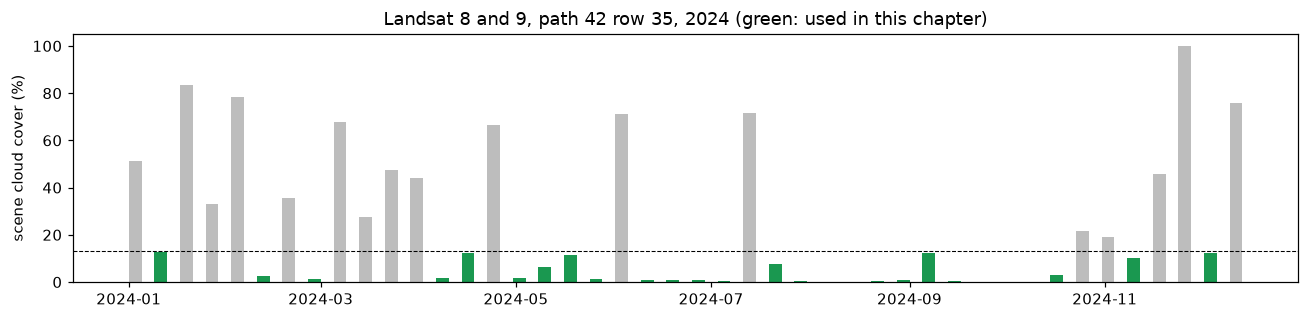

In [2]:
items = catalog.search(collections=["landsat-c2-l2"], bbox=SITE["bbox"], datetime="2024-01-01/2024-12-31",
                       query={"platform": {"in": ["landsat-8", "landsat-9"]}}).item_collection()  # every 2024 scene
scenes = pd.DataFrame([{"id": i.id, "date": i.datetime.date(), "platform": i.properties["platform"],
                        "cloud_cover": i.properties["eo:cloud_cover"]} for i in items])  # one row per scene
scenes = scenes[scenes.id.str.contains("_042035_")].sort_values("date").reset_index(drop=True)  # path 42 row 35 only
print(len(scenes), "scenes on path 42 row 35;", (scenes.cloud_cover < 13).sum(), "with less than 13 % cloud")  # counts
fig, ax = plt.subplots(figsize=(12, 3))  # one panel
ax.bar(pd.to_datetime(scenes.date), scenes.cloud_cover, width=4,
       color=np.where(scenes.cloud_cover < 13, "#1a9850", "#bdbdbd"))  # cloud cover per date
ax.axhline(13, color="k", lw=0.7, ls="--"); ax.set_ylabel("scene cloud cover (%)")  # threshold
ax.set_title("Landsat 8 and 9, path 42 row 35, 2024 (green: used in this chapter)"); plt.tight_layout(); plt.show()  # draw

Landsat 8 and 9 together give an image every 8 days. Winter storms cloud out most January to
March and November to December dates; from April to October almost every pass is clear, which is
why the Central Valley is a good place to learn these models. The list of chosen scenes is kept
in `sd.SEASON_2024`.

## Reading a window and applying scale factors

The main scene is 5 July 2024. Its STAC item lists one asset per band; the metadata give the
projection (UTM zone 11N) and the acquisition time.

In [3]:
item = catalog.get_collection("landsat-c2-l2").get_item(sd.MAIN_SCENE)  # one scene
epsg = item.properties.get("proj:epsg") or int(item.properties["proj:code"].split(":")[1])  # its UTM zone
print(item.id, "| EPSG", epsg, "|", item.properties["datetime"])  # identity
print("assets:", ", ".join(sorted(k for k in item.assets if k not in ("rendered_preview", "tilejson"))))  # bands and files

LC08_L2SP_042035_20240705_02_T1 | EPSG 32611 | 2024-07-05T18:33:27.252130Z
assets: ang, atran, blue, cdist, coastal, drad, emis, emsd, green, lwir11, mtl.json, mtl.txt, mtl.xml, nir08, qa, qa_aerosol, qa_pixel, qa_radsat, red, swir16, swir22, trad, urad


In [4]:
from pyproj import Transformer  # coordinate transformations

to_utm = Transformer.from_crs(4326, epsg, always_xy=True)  # lon/lat -> UTM
b = SITE["bbox"]  # west, south, east, north
xs, ys = to_utm.transform([b[0], b[2], b[0], b[2]], [b[1], b[1], b[3], b[3]])  # the four corners in UTM
x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)  # window that covers the box

red_dn = rioxarray.open_rasterio(item.assets["red"].href).squeeze("band", drop=True)  # lazy: nothing read yet
print("full scene:", dict(red_dn.sizes))  # whole scene size
red_dn = red_dn.sel(x=slice(x0, x1), y=slice(y1, y0)).load()  # read only the window
print("window:", dict(red_dn.sizes), "| dtype", red_dn.dtype, "| DN range", int(red_dn.min()), "to", int(red_dn.max()))  # what was read

full scene: {'y': 7951, 'x': 7821}


window: {'y': 953, 'x': 926} | dtype uint16 | DN range 7063 to 34414


Only the window (about 3 % of the scene) is transferred. The values are 16-bit integers; the
Collection 2 scale factors turn them into reflectance and kelvin. A DN of 0 is fill.

In [5]:
red = (red_dn.where(red_dn > 0) * 2.75e-5 - 0.2)  # surface reflectance, 0 to 1
st_dn = rioxarray.open_rasterio(item.assets["lwir11"].href).squeeze("band", drop=True).sel(x=slice(x0, x1), y=slice(y1, y0)).load()  # ST_B10
lst = st_dn.where(st_dn > 0) * 0.00341802 + 149.0  # surface temperature, K
pd.DataFrame({"DN": [float(red_dn.median()), float(st_dn.median())],  # raw medians
              "physical": [float(red.median()), float(lst.median())],  # scaled medians
              "forgotten offset": [float(red_dn.median()) * 2.75e-5, float(st_dn.median()) * 0.00341802]},  # scale without offset
             index=["red reflectance", "surface temperature (K)"]).round(3)  # table

,DN,physical,forgotten offset
red reflectance,12805.0,0.152,0.352
surface temperature (K),51283.0,324.286,175.286


Without the offset, the red reflectance would be about 0.2 too high and the surface temperature
149 K too low: errors that no later step can repair.

## Decoding the quality band

`QA_PIXEL` packs one flag per bit. Bits 0 to 5 mark fill, dilated cloud, cirrus, cloud, cloud
shadow and snow; bit 7 marks water. A pixel is clear when none of bits 0 to 5 is set.

In [6]:
qa = rioxarray.open_rasterio(item.assets["qa_pixel"].href).squeeze("band", drop=True).sel(x=slice(x0, x1), y=slice(y1, y0)).load().astype("int64")  # QA_PIXEL
BITS = {"fill": 0, "dilated cloud": 1, "cirrus": 2, "cloud": 3, "cloud shadow": 4, "snow": 5, "clear": 6, "water": 7}  # CFMask bits
flags = pd.Series({name: float(((qa >> bit) & 1).mean()) for name, bit in BITS.items()})  # share of pixels with each flag
(100 * flags).round(3).to_frame("% of window")  # table

,% of window
fill,0.000
dilated cloud,0.000
cirrus,0.000
cloud,0.000
cloud shadow,0.000
snow,0.000
clear,100.000
water,0.095


5 July is almost perfectly clear. To see why masks matter, the same decoding on a partly cloudy
scene (16 April 2024, 12 % cloud over the whole scene) shows clouds, their shadows and the cool
fringes around them.

cloud 16.4%, shadow 9.8%, dilation adds 5.1% of the window
median LST: clear 29.8 C | added ring 28.6 C | shadow 24.8 C | cloud 18.7 C


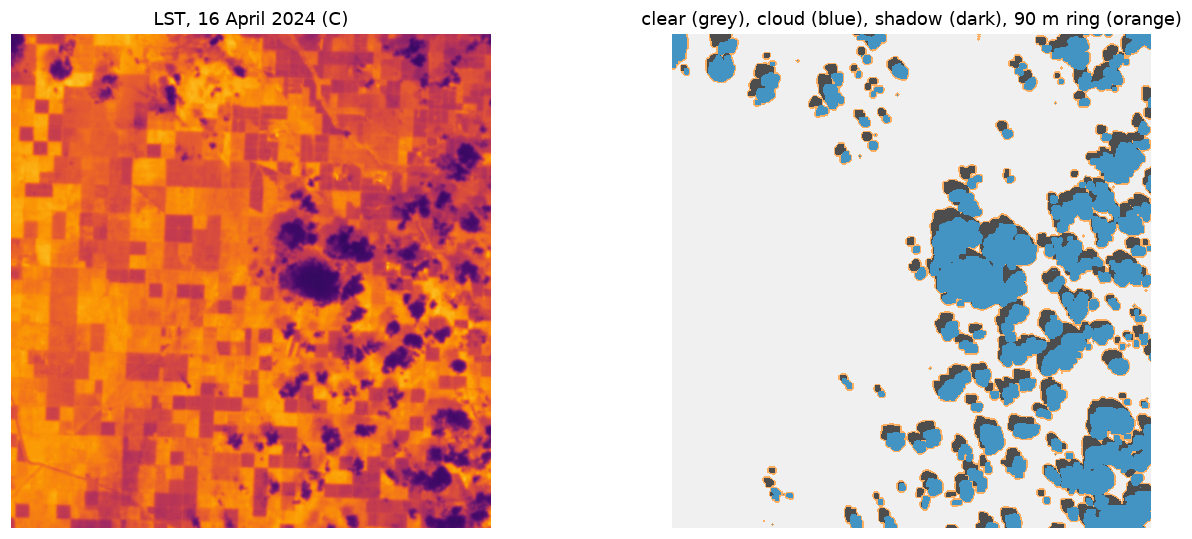

In [7]:
cloudy = sd.load_scene("LC08_L2SP_042035_20240416_02_T1")  # cached stack of a partly cloudy scene (raw QA not kept)
it2 = catalog.get_collection("landsat-c2-l2").get_item(cloudy.attrs["scene_id"])  # its STAC item
qa2 = rioxarray.open_rasterio(it2.assets["qa_pixel"].href).squeeze("band", drop=True).sel(x=slice(x0, x1), y=slice(y1, y0)).load().astype("int64")  # its QA_PIXEL
cloud = (((qa2 >> 3) & 1) | ((qa2 >> 1) & 1)).astype(bool)  # cloud or dilated cloud
shadow = ((qa2 >> 4) & 1).astype(bool)  # cloud shadow
buffer = ndimage.binary_dilation((cloud | shadow).values, iterations=3)  # three more pixels (90 m) around them
lst2 = cloudy.lst - 273.15  # its surface temperature, C
ring = buffer & ~(cloud | shadow).values  # the 90 m ring the dilation adds
print(f"cloud {cloud.mean().item():.1%}, shadow {shadow.mean().item():.1%}, dilation adds {ring.mean():.1%} of the window")  # sizes
print(f"median LST: clear {float(lst2.where(~buffer).median()):.1f} C | added ring {float(lst2.where(ring).median()):.1f} C | "
      f"shadow {float(lst2.where(shadow).median()):.1f} C | cloud {float(lst2.where(cloud).median()):.1f} C")  # temperatures

fig, ax = plt.subplots(1, 2, figsize=(13, 5))  # two maps
ax[0].imshow(lst2, cmap="inferno", vmin=0, vmax=45); ax[0].set_title("LST, 16 April 2024 (C)")  # temperature
show = np.where(cloud, 3, np.where(shadow, 2, np.where(ring, 1, 0)))  # 0 clear, 1 ring, 2 shadow, 3 cloud
ax[1].imshow(show, cmap=plt.matplotlib.colors.ListedColormap(["#f0f0f0", "#fdae61", "#4d4d4d", "#4393c3"]), vmin=0, vmax=3, interpolation="nearest")  # masks
ax[1].set_title("clear (grey), cloud (blue), shadow (dark), 90 m ring (orange)")  # legend in the title
for a in ax:  # both maps
    a.axis("off")  # hide axes
plt.tight_layout(); plt.show()  # draw

Clouds and their shadows are far cooler than the clear land, and the ring of pixels the dilation
adds is cooler than the clear median too. Those ring pixels look like well watered vegetation
to an anchor search. `sd.read_landsat` excludes every flagged pixel (bits 0 to 5), which already
includes CFMask's own dilated cloud bit; notebook 05 adds a homogeneity test to the anchor
search for the same reason.

## Overpass time and sun angles

The scene centre time and the sun elevation and azimuth come with the metadata.
`seb.scene_geometry` reads them from STAC properties or from a Landsat MTL file, and
`seb.solar_position` computes the same angles from the time and position, which is a useful
check (and what you need for sensors without these fields).

In [8]:
geo = seb.scene_geometry(item.properties)  # from the STAC properties
pos = seb.solar_position(SITE["lat"], SITE["lon"], geo["datetime"])  # computed at the window centre
local = geo["datetime"] + pd.Timedelta(hours=SITE["utc_offset"])  # Pacific daylight time
pd.DataFrame({"metadata (scene centre)": [geo["sun_elevation"], geo["sun_azimuth"]],  # what USGS reports
              "computed (window centre)": [float(pos["elevation"]), float(pos["azimuth"])]},  # what seb computes
             index=["sun elevation (deg)", "sun azimuth (deg)"]).round(2).assign(  # table
    note=[f"overpass {geo['datetime']:%H:%M} UTC = {local:%H:%M} local", f"day {geo['doy']}, Earth-Sun factor dr = {geo['dr']:.4f}"])  # time and distance

,metadata (scene centre),computed (window centre),note
sun elevation (deg),66.53,65.93,overpass 18:33 UTC = 11:33 local
sun azimuth (deg),118.61,118.57,"day 187, Earth-Sun factor dr = 0.9671"


The metadata refer to the centre of the whole scene, about 90 km from the window centre, so the
sun elevation differs by about 0.6 degree and the azimuth by less; the computed angles are the
right ones for the window. `dr` is below 1 in early July because the Earth is near its farthest point from the sun
(aphelion), so sunlight is about 3 % weaker than the annual mean.

## Elevation on the Landsat grid

`sd.dem_on` merges the Copernicus DEM tiles around the window and reprojects them bilinearly to
the Landsat grid. Elevation sets air pressure (needed for air density and the psychrometric
constant), and slope and aspect change the incoming sunshine on hillsides.

elevation 43 to 140 m | slope above 5 deg: 0.0% | pressure 99.65 to 100.79 kPa


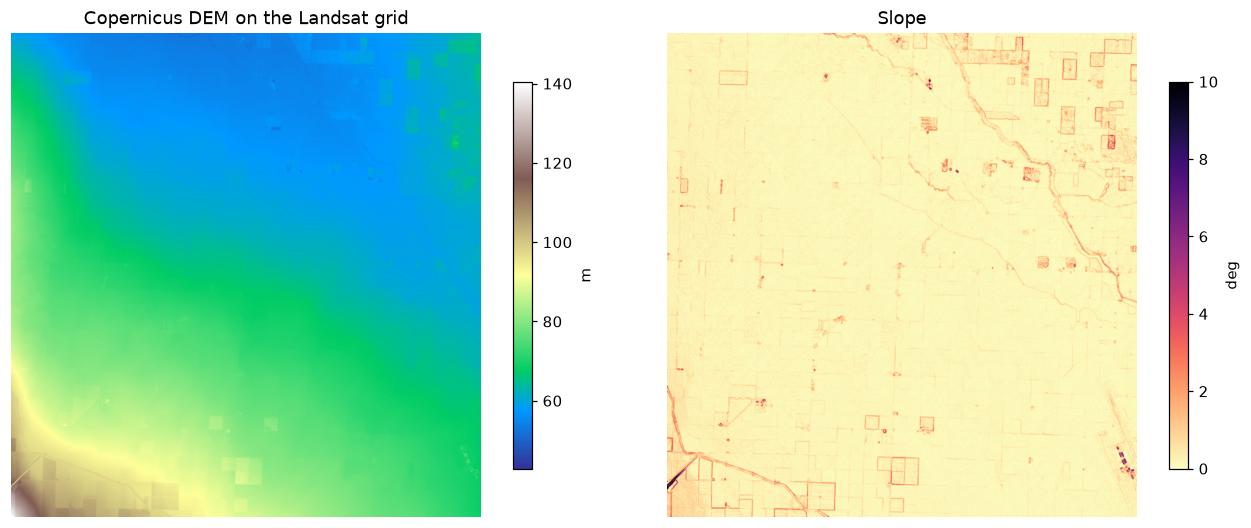

In [9]:
lst_grid = lst.rio.write_crs(epsg)  # the Landsat grid with its CRS
dem = sd.dem_on(lst_grid, SITE)  # elevation on that grid, m
slope, aspect = seb.slope_aspect(dem)  # degrees
pressure = seb.pressure_from_elevation(dem)  # kPa
print(f"elevation {float(dem.min()):.0f} to {float(dem.max()):.0f} m | slope above 5 deg: {float((slope > 5).mean()):.1%} | "
      f"pressure {float(pressure.min()):.2f} to {float(pressure.max()):.2f} kPa")  # ranges
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))  # two maps
im = ax[0].imshow(dem, cmap="terrain"); plt.colorbar(im, ax=ax[0], shrink=0.8, label="m"); ax[0].set_title("Copernicus DEM on the Landsat grid")  # elevation
im = ax[1].imshow(slope, cmap="magma_r", vmax=10); plt.colorbar(im, ax=ax[1], shrink=0.8, label="deg"); ax[1].set_title("Slope")  # slope
for a in ax:  # both maps
    a.axis("off")  # hide axes
plt.tight_layout(); plt.show()  # draw

The valley floor is nearly flat, so terrain corrections of radiation are small here; they matter
in hilly scenes and are included in notebook 03 for completeness.

## Crop types on the Landsat grid

The Cropland Data Layer is in USA Contiguous Albers (EPSG:5070). `sd.cdl_on` asks the CropScape
service for a clip, then reprojects it to the Landsat grid with the nearest neighbour so every
pixel keeps a valid class code.

In [10]:
cdl = sd.cdl_on(lst_grid, SITE, 2024)  # CDL 2024 on the Landsat grid
codes, counts = np.unique(cdl.values, return_counts=True)  # pixels per class
share = pd.Series(100 * counts / counts.sum(), index=codes).sort_values(ascending=False)  # percent per class
top = share.head(12)  # the most common classes
pd.DataFrame({"class": [sd.cdl_name(c) for c in top.index], "% of window": top.round(1).values}, index=top.index)  # table

,class,% of window
204,Pistachios,18.4
61,Fallow/idle cropland,16.5
75,Almonds,9.2
54,Tomatoes,9.0
69,Grapes,6.3
176,Grassland/pasture,5.6
24,Winter wheat,5.5
2,Cotton,4.7
208,Garlic,2.1
122,"Developed, low intensity",2.1


Pistachios and almonds (permanent orchards), fallow land, tomatoes and grapes dominate. Fallow
land is a large share of the Westside in recent years, as surface water deliveries were cut and
groundwater pumping restricted: exactly the contrast between irrigated and dry fields that the
anchors need.

## Weather at the overpass

`seb.weather_open_meteo` returns ERA5 reanalysis from the free Open-Meteo archive (no key): hourly
air temperature, humidity, dew point, wind at 10 m, shortwave radiation and pressure, in UTC.
ERA5 is a 0.25 degree (about 25 km) product, so it describes the regional air rather than any
single field. Notebook 02 compares it with gridMET and discusses what that means over irrigated
land.

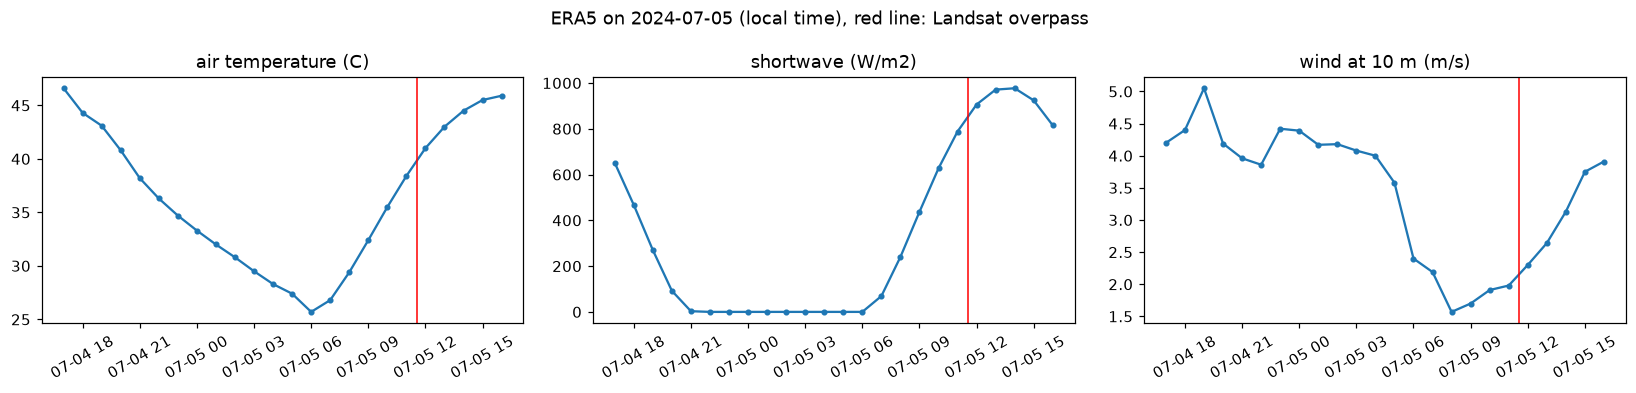

temperature_2m            39.85
relative_humidity_2m       9.33
dew_point_2m               1.83
wind_speed_10m             2.16
shortwave_radiation      853.79
surface_pressure        1004.11
Name: 2024-07-05 18:33:27.252130, dtype: float64

In [11]:
day = geo["datetime"].strftime("%Y-%m-%d")  # the overpass date
w = sd.weather(SITE, day, day)  # cached Open-Meteo hourly and daily tables
hourly = w["hourly"]  # hourly ERA5, UTC
wx = seb.interpolate_weather(hourly, geo["datetime"])  # linear interpolation to the overpass time
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))  # three panels
local_h = hourly.index + pd.Timedelta(hours=SITE["utc_offset"])  # local time axis
for a, col, lab in zip(ax, ["temperature_2m", "shortwave_radiation", "wind_speed_10m"],
                       ["air temperature (C)", "shortwave (W/m2)", "wind at 10 m (m/s)"]):  # each variable
    a.plot(local_h, hourly[col], "o-", ms=3); a.axvline(local, color="r", lw=1)  # hourly series and overpass
    a.set_title(lab); a.tick_params(axis="x", rotation=30)  # labels
plt.suptitle(f"ERA5 on {day} (local time), red line: Landsat overpass"); plt.tight_layout(); plt.show()  # draw
wx[["temperature_2m", "relative_humidity_2m", "dew_point_2m", "wind_speed_10m", "shortwave_radiation", "surface_pressure"]].round(2)  # values at the overpass

ERA5 hourly values are averages over the hour ending at the time stamp, so linear interpolation
between the two neighbouring hours gives the best estimate at 18:33 UTC. The models need vapour
pressure (from the dew point) and wind at 2 m and at the 200 m blending height, where wind is
assumed independent of the surface below (notebook 04).

In [12]:
ea = float(seb.actual_vapour_pressure(t_dew_c=wx["dew_point_2m"]))  # vapour pressure, kPa
u2 = float(seb.wind_2m(wx["wind_speed_10m"], 10.0))  # FAO-56 log profile from 10 m to 2 m
u200 = float(seb.wind_at_blending_height(u2, z=2.0))  # over grass, extended to 200 m
es = float(seb.saturation_vapour_pressure(wx["temperature_2m"]))  # saturation vapour pressure, kPa
print(f"vapour pressure {ea:.2f} kPa, vapour pressure deficit {es - ea:.2f} kPa")  # humidity terms
print(f"wind: {wx['wind_speed_10m']:.2f} m/s at 10 m -> {u2:.2f} m/s at 2 m -> {u200:.2f} m/s at 200 m")  # wind profile

vapour pressure 0.70 kPa, vapour pressure deficit 6.62 kPa
wind: 2.16 m/s at 10 m -> 1.61 m/s at 2 m -> 3.12 m/s at 200 m


A vapour pressure deficit above 6 kPa is extreme; typical summer afternoons in the valley reach
3 to 5 kPa. Together with the strong sunshine, it drives the very high reference ET of this day.

## Saving the stack

All layers share one grid, so they go into one `xr.Dataset` with the overpass weather and
geometry as attributes. `sd.load_scene` does exactly this (plus the thermal radiance terms used
in notebook 03) and caches the result as compressed NetCDF; here the hand-built layers are
compared with the cached stack.

In [13]:
ds = sd.load_scene(sd.MAIN_SCENE)  # the cached stack (built on first use)
same = {"red": float(np.nanmax(np.abs(ds.red - red.astype("float32")))),  # hand-built vs cached reflectance
        "lst": float(np.nanmax(np.abs(ds.lst - lst.astype("float32")))),  # surface temperature
        "dem": float(np.nanmax(np.abs(ds.dem - dem))),  # elevation
        "cdl": int((ds.cdl != cdl).sum())}  # crop codes that differ
print("largest differences, hand-built vs sd.load_scene:", same)  # should be zero
print(list(ds.data_vars))  # layers
{k: ds.attrs[k] for k in ["scene_id", "datetime", "sun_elevation", "dr", "t_air_c", "ea_kpa", "u10", "rs_wm2", "tmax_c", "tmin_c", "rs_daily_mj"]}  # key attributes

largest differences, hand-built vs sd.load_scene: {'red': 0.0, 'lst': 0.0, 'dem': 0.0, 'cdl': 0}
['blue', 'green', 'red', 'nir', 'swir16', 'swir22', 'lst', 'emis', 'trad', 'urad', 'drad', 'atran', 'clear', 'water', 'dem', 'cdl']


{'scene_id': 'LC08_L2SP_042035_20240705_02_T1',
 'datetime': '2024-07-05 18:33:27.252130',
 'sun_elevation': np.float64(66.53478788),
 'dr': np.float64(0.9670989613924745),
 't_air_c': np.float64(39.84968209388889),
 'ea_kpa': np.float64(0.6970576523011204),
 'u10': np.float64(2.1584224115555553),
 'rs_wm2': np.float64(853.7932642611111),
 'tmax_c': np.float64(46.6),
 'tmin_c': np.float64(25.6),
 'rs_daily_mj': np.float64(29.65)}

## Every clear scene of 2024

Notebook 10 builds a seasonal ET record from every clear 2024 scene. The stacks are built here
in parallel processes (each scene takes one to two minutes to download the first time; later
runs read the cache).

In [14]:
from concurrent.futures import ProcessPoolExecutor  # parallel downloads


with ProcessPoolExecutor(4) as pool:  # four scenes at a time
    paths = list(pool.map(sd.build_scene, sd.SEASON_2024))  # build or find every cached stack

rows = []  # one summary row per scene
for p in paths:  # every stack
    with xr.open_dataset(p) as s:  # read lazily
        rows.append({"scene": s.attrs["scene_id"], "date": pd.Timestamp(s.attrs["datetime"]).date(),
                     "platform": s.attrs["platform"], "clear %": round(100 * float(s.clear.mean()), 1),
                     "air C": round(s.attrs["t_air_c"], 1), "daily max C": s.attrs["tmax_c"],
                     "MB": round(Path(p).stat().st_size / 2**20, 1)})  # summary
season = pd.DataFrame(rows)  # table
print(len(season), "stacks,", round(season.MB.sum()), "MB in total")  # cache size
season.set_index("date")  # table

27 stacks, 563 MB in total


,scene,platform,clear %,air C,daily max C,MB
date,,,,,,
2024-01-11,LC08_L2SP_042035_20240111_02_T1,landsat-8,99.9,8.5,13.7,20.0
2024-02-12,LC08_L2SP_042035_20240212_02_T1,landsat-8,100.0,12.6,15.9,20.5
2024-02-28,LC08_L2SP_042035_20240228_02_T1,landsat-8,100.0,15.6,19.9,20.9
2024-04-08,LC09_L2SP_042035_20240408_02_T1,landsat-9,100.0,16.5,21.0,20.2
2024-04-16,LC08_L2SP_042035_20240416_02_T1,landsat-8,77.0,20.3,24.2,21.9
2024-05-02,LC08_L2SP_042035_20240502_02_T1,landsat-8,100.0,25.5,29.4,20.8
2024-05-10,LC09_L2SP_042035_20240510_02_T1,landsat-9,100.0,29.3,33.3,21.0
2024-05-18,LC08_L2SP_042035_20240518_02_T1,landsat-8,100.0,28.8,34.6,21.0
2024-05-26,LC09_L2SP_042035_20240526_02_T1,landsat-9,100.0,25.1,31.2,21.1


Inside the window only two of the 27 scenes are partly cloudy: 16 April (77 % clear) and 10
November (25 % clear). The scene cloud cover in the metadata describes the whole 185 km scene,
so it can be high while a small window is clear, and the reverse. The later notebooks drop cloudy
pixels with the `clear` layer, and notebook 10 decides which dates are usable for each pixel.

## Summary and exercises

- STAC search plus Cloud-Optimized GeoTIFFs give a small study window from each scene without
  downloading whole scenes: 27 Landsat 8 and 9 scenes of 2024 passed the 13 % cloud filter on
  path 42 row 35.
- Collection 2 values must be scaled (`DN 0.0000275 - 0.2` for reflectance,
  `DN 0.00341802 + 149` K for temperature); the offset matters.
- `QA_PIXEL` bits 0 to 5 flag fill, dilated cloud, cirrus, cloud, shadow and snow. Cloud
  fringes are cool and would make false cold anchors, so masks are generous.
- Elevation (bilinear) and crop codes (nearest) go on the Landsat grid; weather is interpolated
  to the overpass and wind moved to 2 m and 200 m.
- `sd.load_scene` reproduces all of this and caches one NetCDF per scene. Masks are saved as
  plain integers without a fill value: a `_FillValue` of 0 inherited from `QA_PIXEL` would turn
  every cloudy 0 into a missing value that reads back as clear.

**Exercises**

1. Count, for every 2024 scene, the share of clear pixels inside the window rather than the
   scene cloud cover from the metadata. Which scenes would you drop?
2. Dilate the 16 April cloud mask by 1, 3 and 6 pixels and plot the median LST of each added
   ring. How far from the cloud does the cooling reach?
3. Compute the sun elevation with `seb.solar_position` at the four corners of the window. How
   large is the difference across 28 km?
4. Download a week of hourly ERA5 around 5 July (`sd.weather(SITE, "2024-07-01", "2024-07-08")`)
   and plot the air temperature at every overpass hour. How unusual was 5 July?